# QuantumXCT — computation-time scaling benchmark

Runtime (and memory) scaling of the pipeline as the number of features grows, written as `n_source + n_target` (total qubits). Reuses the tested helpers from `scaling_benchmark.py` so there is a single source of truth; results are saved to `results/scaling/`.

Where it breaks: candidate screening builds a `2^N x 2^N` density matrix, so memory grows as `4^N`. The sweep predicts this and stops gracefully before a hard OOM (unless you set `allow_oom=True`). Use `scope="inter"` (LR-only) to skip screening and avoid the `4^N` wall.


In [1]:
import os, gc, csv, time, traceback
import numpy as np
# Reuse the exact functions the CLI script uses (no logic duplication)
from scaling_benchmark import run_point, default_pairs, dm_bytes, _plot, OUT_DIR, _TOTAL_RAM

os.makedirs(OUT_DIR, exist_ok=True)
print('RAM detected: %.1f GB | results -> %s' % (_TOTAL_RAM/1e9, OUT_DIR))

RAM detected: 133.7 GB | results -> results/scaling


## Sweep parameters
Edit these, then run the sweep cell. `n_epochs` is kept small so the curve reflects size, not epoch count.


In [2]:
max_qubits       = 20        # largest n_source + n_target to attempt
scope            = 'all'     # dense screening up to 12 qubits, exact sparse screening above
shots            = 5000
n_epochs         = 10
max_greedy_depth = 4
threshold        = 0.002
kl_tol           = 0.01
mem_fraction     = 0.8       # stop before predicted screening memory exceeds this fraction of RAM
allow_oom        = False     # True = ignore the memory prediction and push into the wall (may crash)
time_cap_s       = 7200.0     # stop once a single point exceeds this wall-time
exact_scoring    = True       # exact statevector scoring (needed to reach 10+10 genes; False = shot sampling)
seed             = 42

## Run the sweep
Writes `results/scaling/scaling_results.csv` incrementally (earlier points survive a crash) and prints a live table.


In [3]:
np.random.seed(seed)
csv_path = os.path.join(OUT_DIR, 'scaling_results.csv')
fields = ['n_source','n_target','total_qubits','n_candidates','n_gates',
          't_encode_s','t_screen_s','t_search_s','t_optimize_s','t_total_s',
          'dm_mem_est_GB','rss_delta_GB','scoring','status']
rows = []
print(f"{'size':>8} {'qubits':>6} {'cand':>5} {'gates':>5} {'screen(s)':>10} {'search(s)':>10} {'total(s)':>9} {'DMmem(GB)':>10}")
with open(csv_path, 'w', newline='') as f:
    writer = csv.DictWriter(f, fieldnames=fields); writer.writeheader()
    for (n1, n2) in default_pairs(max_qubits):
        N = n1 + n2
        if scope != 'inter' and N <= 12:   # dense screening only up to 12 qubits
            est = dm_bytes(N)
            if not allow_oom and est > mem_fraction * _TOTAL_RAM:
                row = {k: '' for k in fields}
                row.update({'n_source': n1, 'n_target': n2, 'total_qubits': N,
                            'dm_mem_est_GB': round(est/1e9, 2), 'status': 'stopped: predicted OOM'})
                writer.writerow(row); f.flush(); rows.append(row)
                print(f'  {n1}+{n2:<5} {N:>6}  -- predicted screening memory {est/1e9:.1f} GB > '
                      f'{mem_fraction*100:.0f}% RAM -> stopping (set allow_oom=True or scope="inter")')
                break
        try:
            r = run_point(n1, n2, scope, shots, n_epochs, max_greedy_depth, threshold, kl_tol, seed=seed,
                          exact=exact_scoring)
            writer.writerow(r); f.flush(); rows.append(r)
            print(f"  {n1}+{n2:<5} {N:>6} {r['n_candidates']:>5} {r['n_gates']:>5} "
                  f"{r['t_screen_s']:>10} {r['t_search_s']:>10} {r['t_total_s']:>9} {r['dm_mem_est_GB']:>10}")
            gc.collect()
            if r['t_total_s'] > time_cap_s:
                print(f'  time cap ({time_cap_s}s) exceeded -> stopping.'); break
        except MemoryError:
            row = {k: '' for k in fields}
            row.update({'n_source': n1, 'n_target': n2, 'total_qubits': N, 'status': 'MemoryError'})
            writer.writerow(row); f.flush(); rows.append(row)
            print(f'  {n1}+{n2} -> MemoryError (the wall). Stopping.'); break
        except Exception as e:
            row = {k: '' for k in fields}
            row.update({'n_source': n1, 'n_target': n2, 'total_qubits': N, 'status': f'error: {type(e).__name__}'})
            writer.writerow(row); f.flush(); rows.append(row)
            print(f'  {n1}+{n2} -> {type(e).__name__}: {e}'); traceback.print_exc(); break
print(f'\nCSV written to {csv_path}')

    size qubits  cand gates  screen(s)  search(s)  total(s)  DMmem(GB)

--- CNOT Analysis (abs) ---
Max Signal: 0.2098
Candidates Found: 2 / 2
------------------------------


--- Starting Multi-Epoch Refined Search ---

--- Using provided CNOT candidate list for the search. ---
Number of candidates to be searched: 2
Initial KL divergence (baseline): 0.118506

--- Starting Epoch 1/2 (Addition) with CNOT: (1, 0) (KL: 0.198956) ---
  Skipping epoch: Single CNOT KL (0.198956) does not improve over baseline (0.118506).



--- Starting Epoch 2/2 (Addition) with CNOT: (0, 1) (KL: 0.155530) ---
  Skipping epoch: Single CNOT KL (0.155530) does not improve over baseline (0.118506).

Final Result: Baseline (0 CNOTs) is the best choice (KL: 0.118506).

Total search took: 0.20 seconds.
No CNOT topology provided for CRX optimization. Returning baseline KL sum.


  1+1          2     2     0     0.0004     0.1953    0.2584        0.0

--- CNOT Analysis (abs) ---
Max Signal: 0.1899
Candidates Found: 6 / 6
------------------------------


--- Starting Multi-Epoch Refined Search ---

--- Using provided CNOT candidate list for the search. ---
Number of candidates to be searched: 6
Initial KL divergence (baseline): 0.171539



--- Starting Epoch 1/6 (Addition) with CNOT: (1, 2) (KL: 0.198676) ---
  Skipping epoch: Single CNOT KL (0.198676) does not improve over baseline (0.171539).

--- Starting Epoch 2/6 (Addition) with CNOT: (0, 2) (KL: 0.207503) ---
  Skipping epoch: Single CNOT KL (0.207503) does not improve over baseline (0.171539).



--- Starting Epoch 3/6 (Addition) with CNOT: (1, 0) (KL: 0.255831) ---
  Skipping epoch: Single CNOT KL (0.255831) does not improve over baseline (0.171539).

--- Starting Epoch 4/6 (Addition) with CNOT: (2, 0) (KL: 0.247137) ---
  Skipping epoch: Single CNOT KL (0.247137) does not improve over baseline (0.171539).


...

    --> Found a better KL on this path: 1.963269 at depth 2 with added CNOT (0, 4)


    --> Found a better KL on this path: 1.848456 at depth 3 with added CNOT (8, 7)


  Max depth (4) reached. Stopping search path.
  Epoch 10 best KL Sum: 1.848456
  --> Epoch 10 found a new overall best KL Sum: 1.848456

--- Starting Greedy CNOT Removal Search on Best Found Sequence ---
  Starting removal search with 3 CNOTs (KL Sum: 1.848456)


  No CNOT removal improved the score. Stopping removal search.

Final Result: Best sequence found has 4 CNOTs (KL: 1.780624).

Total search took: 2613.87 seconds.

--- Starting CRX Angle Optimization (4 CRX gates) ---


Return from COBYLA because the trust region radius reaches its lower bound.
Number of function values = 46   Least value of F = 1.6358642989392425   Constraint violation = 0.0
The corresponding X is:
[3.0404447  3.14159265 3.14125981 1.44301781]
The constraint value is:
[-3.04044470e+00 -3.14159265e+00 -3.14125981e+00 -1.44301781e+00
 -1.01147951e-01  0.00000000e+00 -3.32845847e-04 -1.69857484e+00]


Optimization Results:
  Success: True
  Message: Return from COBYLA because the trust region radius reaches its lower bound.
  Optimized Angles: ['3.0404', '3.1416', '3.1413', '1.4430']
CRX Angle Optimization took: 45.19 seconds
  6+6         12   132     4     0.4637  2613.8657 2659.5244     0.2684
  time cap (1200.0s) exceeded -> stopping.

CSV written to results/scaling/scaling_results.csv


## Plot the scaling curve
Time vs total qubits (log y), per stage + total. Saved to `results/scaling/scaling_curve.png`.


Curve written to results/scaling/scaling_curve.png


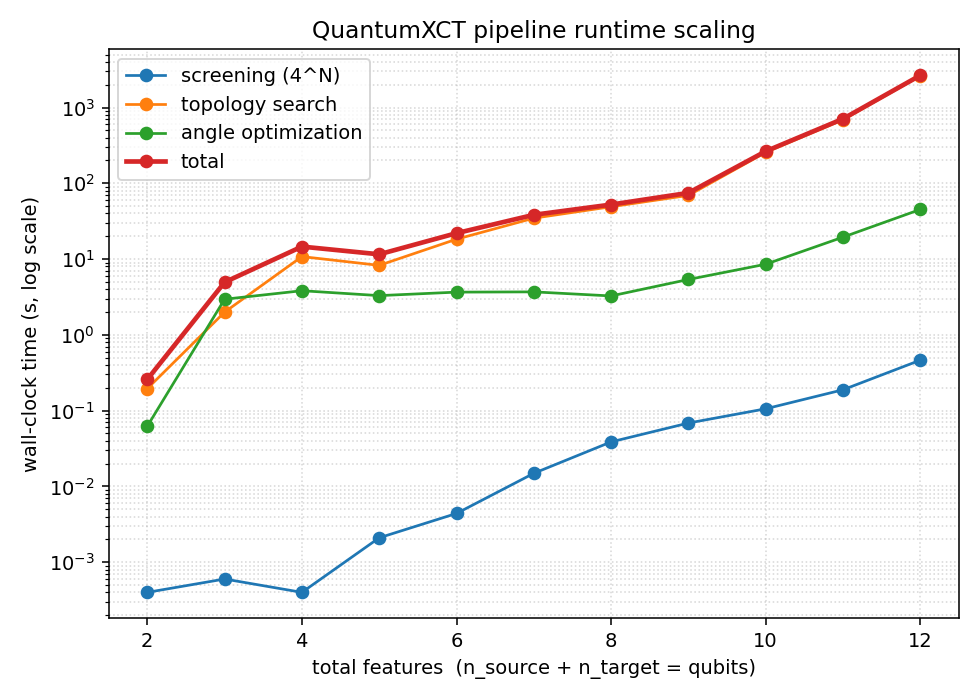

,n_source,n_target,total_qubits,n_candidates,n_gates,t_encode_s,t_screen_s,t_search_s,t_optimize_s,t_total_s,dm_mem_est_GB,rss_delta_GB,status
0,1,1,2,2,0,0.0005,0.0004,0.1953,0.0623,0.2584,0.0000,0.0086,ok
1,2,1,3,6,4,0.0004,0.0006,1.9949,2.9527,4.9486,0.0000,0.0042,ok
2,2,2,4,12,4,0.0002,0.0004,10.7862,3.8234,14.6103,0.0000,0.0061,ok
3,3,2,5,20,4,0.0005,0.0021,8.2617,3.2946,11.5588,0.0000,0.0015,ok
4,3,3,6,30,4,0.0002,0.0044,18.3027,3.6636,21.9709,0.0001,0.0015,ok
5,4,3,7,42,4,0.0003,0.0149,34.6585,3.6923,38.3660,0.0003,0.0015,ok
6,4,4,8,56,4,0.0003,0.0387,49.0508,3.2627,52.3525,0.0010,0.0071,ok
7,5,4,9,72,4,0.0003,0.0686,69.2242,5.3817,74.6748,0.0042,0.0091,ok
8,5,5,10,90,4,0.0003,0.1058,256.0065,8.5536,264.6662,0.0168,0.0171,ok
9,6,5,11,110,4,0.0004,0.1886,689.4632,19.4876,709.1398,0.0671,0.0120,ok


In [4]:
import pandas as pd
_plot(rows)   # writes results/scaling/scaling_curve.png
from IPython.display import Image, display
png = os.path.join(OUT_DIR, 'scaling_curve.png')
display(Image(png)) if os.path.exists(png) else print('Not enough successful points to plot.')
pd.DataFrame(rows)